C:\Users\Mahdieh\AppData\Local\Temp\ipykernel_30192\4097533496.py:33: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  multiomics_df['patient_id'] = multiomics_df[mol_id_col].astype(str).str.extract(r'(TCGA-[A-Z0-9]{2}-[A-Z0-9]{4})')[0]
C:\Users\Mahdieh\AppData\Local\Temp\ipykernel_30192\4097533496.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=stage_col[0], y=sample_gene, data=merged_plot_df, palette='Set2')


<Figure size 800x500 with 0 Axes>

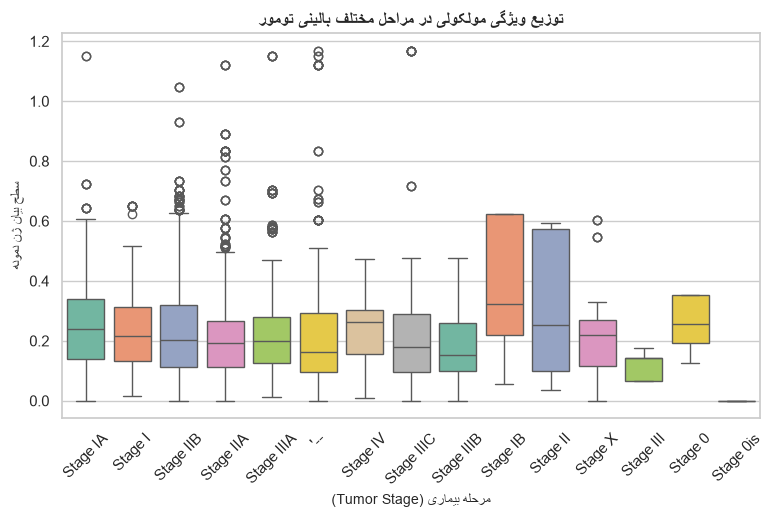

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# بارگذاری داده‌ها با مسیرهای مطلق سیستم شما
clinical_df = pd.read_csv(r'E:\Uni\Statistics\Project\data\clinical.tsv', sep='\t', low_memory=False)
multiomics_df = pd.read_csv(r'E:\Uni\Statistics\Project\data\multiomics.csv', low_memory=False)

# ۳. نمودار توزیع زمان پیگیری / بقا (Follow-up / Survival Time)
plt.figure(figsize=(8, 5))
time_col = [c for c in clinical_df.columns if 'time' in c.lower() and ('follow' in c.lower() or 'surviv' in c.lower())]
if time_col:
    survival_years = pd.to_numeric(clinical_df[time_col[0]], errors='coerce') / 365.25
    sns.histplot(survival_years.dropna(), kde=True, color='purple', bins=30)
    plt.title('توزیع زمان پیگیری بیماران (Follow-up Time Distribution)', fontsize=12, fontweight='bold')
    plt.xlabel('زمان پیگیری (سال)', fontsize=10)
    plt.ylabel('فراوانی (تعداد بیماران)', fontsize=10)
    plt.savefig(r'E:\Uni\Statistics\Project\figures\survival_time_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()

# ۴. نمودار جعبه‌ای (Boxplot) مقایسه یک ویژگی مولکولی در مراحل مختلف تومور (با تطبیق شناسه‌های بیمار)
stage_col = [c for c in clinical_df.columns if 'stage' in c.lower() and ('pathologic' in c.lower() or 'overall' in c.lower())]

if stage_col and len(multiomics_df.columns) > 1:
    # پیدا کردن ستون شناسه‌ها
    clin_id_col = [c for c in clinical_df.columns if 'submitter_id' in c or 'barcode' in c][0]
    mol_id_col = multiomics_df.columns[0]
    
    # استخراج کدهای استاندارد بیمار (TCGA-XX-XXXX) برای تطبیق دقیق
    clinical_df['patient_id'] = clinical_df[clin_id_col].astype(str).str.extract(r'(TCGA-[A-Z0-9]{2}-[A-Z0-9]{4})')[0]
    multiomics_df['patient_id'] = multiomics_df[mol_id_col].astype(str).str.extract(r'(TCGA-[A-Z0-9]{2}-[A-Z0-9]{4})')[0]
    
    # انتخاب یک ژن نمونه از فایل مولکولی (ستون دوم)
    sample_gene = multiomics_df.columns[1]
    
    # ادغام دو جدول بر اساس شناسه‌های یکتا
    merged_plot_df = pd.merge(
        clinical_df[['patient_id', stage_col[0]]].dropna(),
        multiomics_df[['patient_id', sample_gene]].dropna(),
        on='patient_id',
        how='inner'
    )
    
    # تبدیل مقادیر ژن به عدد
    merged_plot_df[sample_gene] = pd.to_numeric(merged_plot_df[sample_gene], errors='coerce')
    merged_plot_df = merged_plot_df.dropna(subset=[sample_gene])
    
    # رسم نمودار جعبه‌ای
    plt.figure(figsize=(9, 5))
    sns.boxplot(x=stage_col[0], y=sample_gene, data=merged_plot_df, palette='Set2')
    plt.title('توزیع ویژگی مولکولی در مراحل مختلف بالینی تومور', fontsize=12, fontweight='bold')
    plt.xlabel('مرحله بیماری (Tumor Stage)', fontsize=10)
    plt.ylabel('سطح بیان ژن نمونه', fontsize=10)
    plt.xticks(rotation=45)
    plt.savefig(r'E:\Uni\Statistics\Project\figures\molecular_vs_stage_boxplot.png', dpi=300, bbox_inches='tight')
    plt.show()